In [82]:
import pyarrow
import matplotlib.pyplot as plt

In [54]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
df = pd.read_csv(PROJECT_ROOT / "data" / "spotify-top-200-dataset.csv", delimiter=";")
print(df.head())

                 track_id                               track_name  \
0  5aAx2yezTd8zXrkmtKl66Z                                  Starboy   
1  5aAx2yezTd8zXrkmtKl66Z                                  Starboy   
2  7BKLCZ1jbUBVqRi2FVlTVw                                   Closer   
3  7BKLCZ1jbUBVqRi2FVlTVw                                   Closer   
4  5knuzwU65gJK7IF5yJsuaW  Rockabye (feat. Sean Paul & Anne-Marie)   

   track_popularity  track_number                album_id  \
0                 0             1  09fggMHib4YkOtwQNXEBII   
1                 0             1  09fggMHib4YkOtwQNXEBII   
2                84             1  0rSLgV8p5FzfnqlEk4GzxE   
3                84             1  0rSLgV8p5FzfnqlEk4GzxE   
4                75             1  3meZFplbMmji648oWUNEfQ   

                                album_name  \
0                                  Starboy   
1                                  Starboy   
2                                   Closer   
3                           

In [55]:
print(df.shape) #74660 rows, 40 columns
print(df.columns.tolist())

(74660, 40)
['track_id', 'track_name', 'track_popularity', 'track_number', 'album_id', 'album_name', 'album_img', 'album_type', 'album_label', 'album_track_number', 'album_popularity', 'artist_num', 'artist_names', 'artist_id', 'artist_name', 'artist_img', 'artist_followers', 'artist_popularity', 'artist_genres', 'rank', 'week', 'collab', 'explicit', 'release_date', 'danceability', 'energy', 'key', 'mode', 'time_signature', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration', 'pivot', 'streams', 'track_index']


In [56]:
#filtering so it is one row per track-week; dropping duplicate collaborator entries
print(df['pivot'].dtype)
panel = df[df['pivot'] == 0]
print(panel.shape) #44200 rows, 40 columns remaining

int64
(44200, 40)


In [ ]:
#ASIDE: cleaning the release_date column
bad_release_dates = panel[panel["release_date"].str.len() != 10] #release dates that are not in the format MM/DD/YYYY
print(len(bad_release_dates))
print(bad_release_dates["release_date"].unique()) 
print(len(bad_release_dates[bad_release_dates["release_date"] == '0000'])) #release dates that are 0000

panel['release_date'] = panel['release_date'].replace('0000', pd.NA) #replace 0000 with NA

589
<ArrowStringArray>
[   '2015',    '2013',    '2012',    '2008',    '2017',    '0000',    '1948',
    '1991',    '1990',    '2002',    '1965',    '1963',    '1981',    '2003',
    '2011',    '2000',    '1962', '1957-09',    '1947',    '2019',    '2016',
    '1998',    '1971',    '2001',    '1994',    '2004']
Length: 26, dtype: str
5


In [ ]:
print(panel['week'].iloc[300], type(panel['week'].iloc[0])) #format is MM/DD/YYYY
print(panel['release_date'].iloc[0], type(panel['release_date'].iloc[0])) #format is YYYY-MM-DD

#converting week and release_date to datetime
panel['week'] = pd.to_datetime(panel['week'], format='%m/%d/%Y')
panel['release_date'] = pd.to_datetime(panel['release_date'], format='mixed') #mixed format to address cases where release_date is not in the format MM/DD/YYYY

print(panel['week'].iloc[300], type(panel['week'].iloc[0]))
print(panel['release_date'].iloc[0], type(panel['release_date'].iloc[0]))

print(panel['week'].min(), panel['week'].max()) #2017-01-06 to 2021-04-16
print(panel['release_date'].min(), panel['release_date'].max()) #1942-01-01 to 2021-04-15

#print number of unique weeks and release dates
print(panel['week'].nunique(), panel['release_date'].nunique()) #221 weeks x 200 tracks per week = 44200 rows in the panel 

print(panel['release_date'].isna().sum()) #5 missing release dates

2017-01-13 00:00:00 <class 'pandas.Timestamp'>
2016-11-25 00:00:00 <class 'pandas.Timestamp'>
2017-01-13 00:00:00 <class 'pandas.Timestamp'>
2016-11-25 00:00:00 <class 'pandas.Timestamp'>
2017-01-06 00:00:00 2021-04-16 00:00:00
1942-01-01 00:00:00 2021-04-15 00:00:00
221 931
5


-25.0 4122.0
479
count    479.000000
mean      -8.647182
std        5.811073
min      -25.000000
25%      -12.000000
50%       -7.000000
75%       -4.000000
max       -1.000000
Name: weeks_since_release, dtype: float64


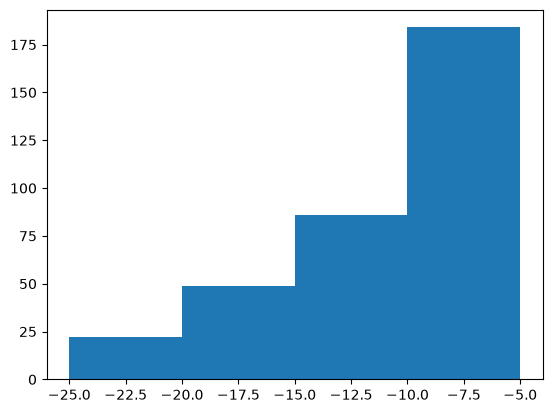

In [ ]:
#Calculating weeks since release to diffrentiate a track's natural post-release hype vs. late life hype via. promotional push
panel['weeks_since_release'] = (panel['week'] - panel['release_date']).dt.days // 7
print(panel['weeks_since_release'].min(), panel['weeks_since_release'].max())

#Number of tracks that were charted before their release
print((panel['weeks_since_release'] < 0).sum())  

charted_before_release = panel[panel['weeks_since_release'] < 0]
print(charted_before_release['weeks_since_release'].describe())

#Creating a histogram of charted_before_release['weeks_since_release'] to visualize the distribution
plt.hist(charted_before_release['weeks_since_release'], bins=range(-25, 0, 5))
plt.show()

Plausable Explanation: There are 479 tracks in the dataset of 44200 tracks total (~1%) that charted before the release date. If the number of weeks since release were negative but close to zero, it could be attributed to pre-release streaming or track leak. However, since some of the tracks charted up to 25 weeks before the release date, a possible explanation is that these tracks were released as singles and then later were put in an album. Therefore, the release date is actually the album's release date rather than the track's original release date. 

How to handle this: these tracks will be filtered out as normal post-release hype events, rather than Discovery Mode/ promotional pushes. 

In [ ]:
#selecting features to keep
clean_panel = panel[['track_id', 'track_name', 'artist_names', 'rank', 'streams', 'weeks_since_release', 'week', 'release_date']]

print(clean_panel.head())
print(clean_panel.shape)

                 track_id                                         track_name  \
0  5aAx2yezTd8zXrkmtKl66Z                                            Starboy   
2  7BKLCZ1jbUBVqRi2FVlTVw                                             Closer   
4  5knuzwU65gJK7IF5yJsuaW            Rockabye (feat. Sean Paul & Anne-Marie)   
7  4pdPtRcBmOSQDlJ3Fk945m                                    Let Me Love You   
9  3NdDpSvN911VPGivFlV5d0  I Don’t Wanna Live Forever (Fifty Shades Darke...   

                          artist_names  rank   streams  weeks_since_release  \
0                The Weeknd, Daft Punk     1  25734078                  6.0   
2             The Chainsmokers, Halsey     2  23519705                 23.0   
4  Clean Bandit, Sean Paul, Anne-Marie     3  21216399                 11.0   
7              DJ Snake, Justin Bieber     4  19852704                 22.0   
9                   ZAYN, Taylor Swift     5  18316326                  4.0   

        week release_date  
0 2017-01-06   2

In [83]:
#saving the clean panel
clean_panel.to_parquet(PROJECT_ROOT / "data" / "clean_panel.parquet", index=False) #working with parquet file to preserve the datetime format
clean_panel.to_csv(PROJECT_ROOT / "data" / "clean_panel.csv", index=False) #saving as csv to check the data